# Marine Heatwaves

Projected marine-heatwave (MHW) days per year by category (Hobday et al. 2018) averaged over the selected country's EEZ, from the CMIP6 MHW statistics of Holbrook et al. for SSP1-2.6 and SSP5-8.5.

```{glue:figure} mhw_fig
:scale: 60%
:align: right
```

**Figure. EEZ-average MHW days per year by category.** Ensemble mean (lines) ± one standard deviation across models (shading); vertical lines mark the years at which each scenario reaches the warming levels.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Projection plotting utilities come from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository (`ind_setup.plotting_projections`); data access, site configuration and output helpers come from `functions/projections.py` and `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
from ind_setup.plotting_projections import plot_stacked_mhw_by_warming, plot_mhw_ensemble_mean_std, plot_violin_mhw_categories_by_warming, plot_box_mhw_categories_by_warming,\
    plot_mhw_time_series_by_category, plot_mhw_total_accumulated

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


### Scenarios and global warming levels

Years at which the IPCC AR6 multi-model mean global surface temperature first reaches each warming level (°C above 1850–1900), computed in [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb). Local values are read from every model at those years.

In [5]:
mhw_scenarios = ["ssp126", "ssp585"]
incr_temps = list(prj.WARMING_LEVELS)
delta_t = 0

# Keep only the warming levels each scenario actually reaches
scenario_info = {sc: {wl: v for wl, v in levels.items() if isinstance(v["year"], np.datetime64)}
                 for sc, levels in prj.load_warming_levels(mhw_scenarios).items()}
pd.DataFrame({sc: {f"+{wl}°C": info["year"] for wl, info in levels.items()} for sc, levels in scenario_info.items()})

,ssp126,ssp585
+1.5°C,2032-01-01,2027-01-01
+2.0°C,NaT,2041-01-01
+2.5°C,NaT,2053-01-01
+3.0°C,NaT,2064-01-01


### Get data

Per-model MHW statistics on native ocean grids (`marine_heatwaves/pac_mhw_stats/mhw_cats`). Days per year in each category are averaged over the ocean cells whose centre falls inside the EEZ (cosine-of-latitude weights). The model domain ends at 15°N, so EEZs further north are only partly covered. The result is cached under `data/projections/<site_tag>/mhw_eez.nc`.

In [6]:
eez_geometry = prj.site_eez(country)
ds_mhw = prj.extract_mhw_eez(eez_geometry, country, mhw_scenarios, cache_file=cache_dir / "mhw_eez.nc")
print({sc: int(ds_mhw.mhw_cats_dpy.sel(scenario=sc).isel(region=0, time=0, cat=0).notnull().sum()) for sc in mhw_scenarios}, "models")

{'ssp126': 18, 'ssp585': 18} models


## Analysis

### MHW days per year by category

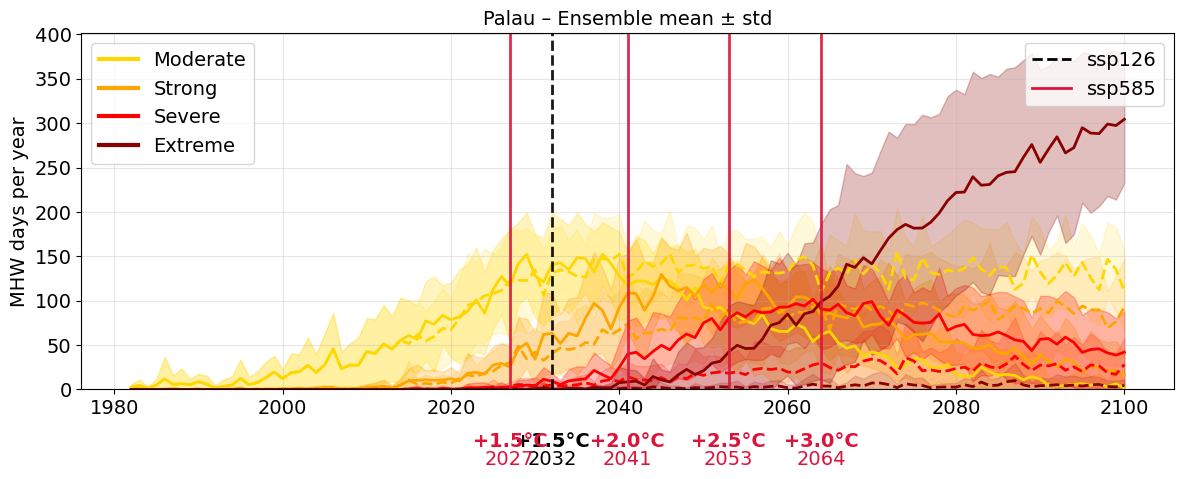

In [7]:
fig, ax = plot_mhw_ensemble_mean_std(ds_mhw, scenario_info, var_analysis="mhw_cats_dpy", scenarios=mhw_scenarios,
                                     warming_levels=incr_temps, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "mhw_timeseries", site_tag)
glue("mhw_fig", fig, display=False)

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_mhw_timeseries_by_category_palau_psw00040309_lat7p337_lon134p477.png')

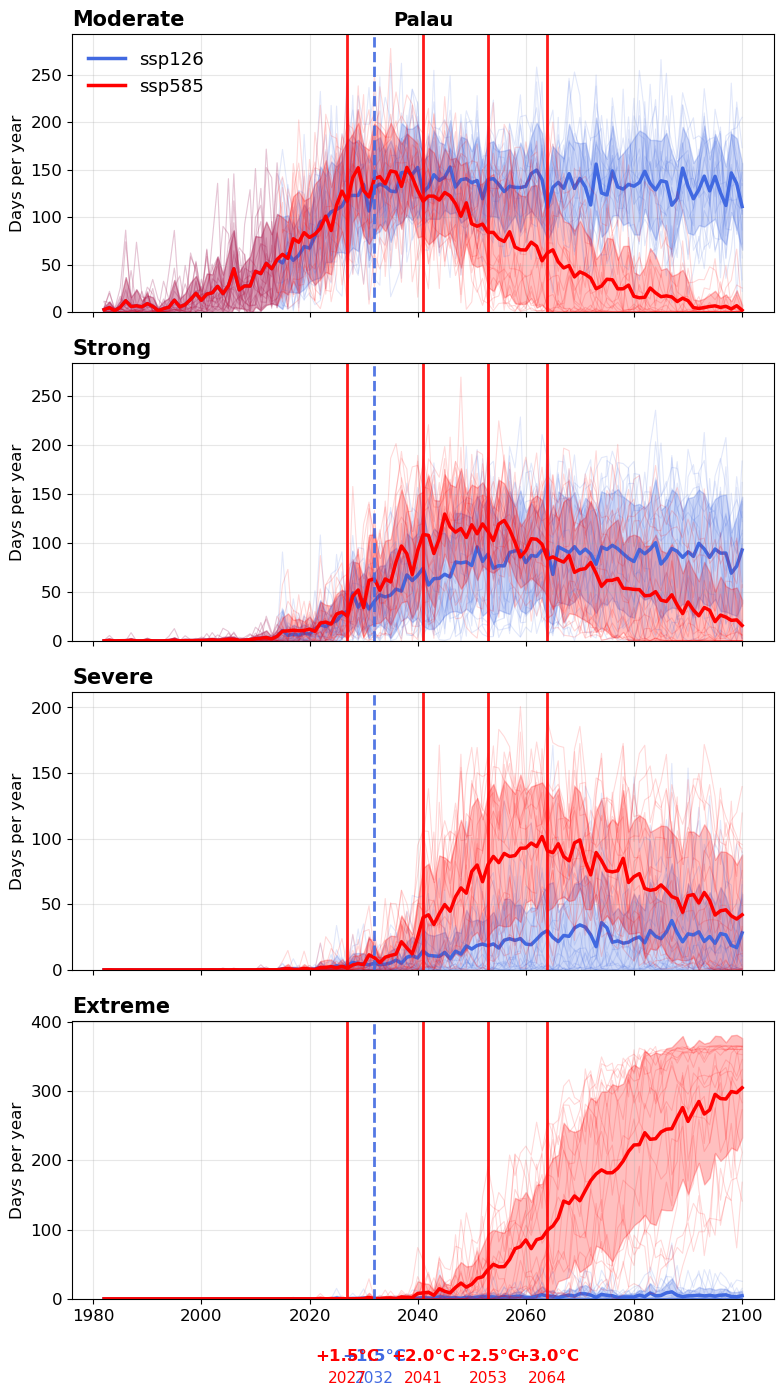

In [8]:
fig, axes = plot_mhw_time_series_by_category(ds_mhw, scenario_info, var_analysis="mhw_cats_dpy", scenarios=mhw_scenarios,
                                             warming_levels=incr_temps, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "mhw_timeseries_by_category", site_tag)

### Days with any MHW category

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_mhw_total_days_palau_psw00040309_lat7p337_lon134p477.png')

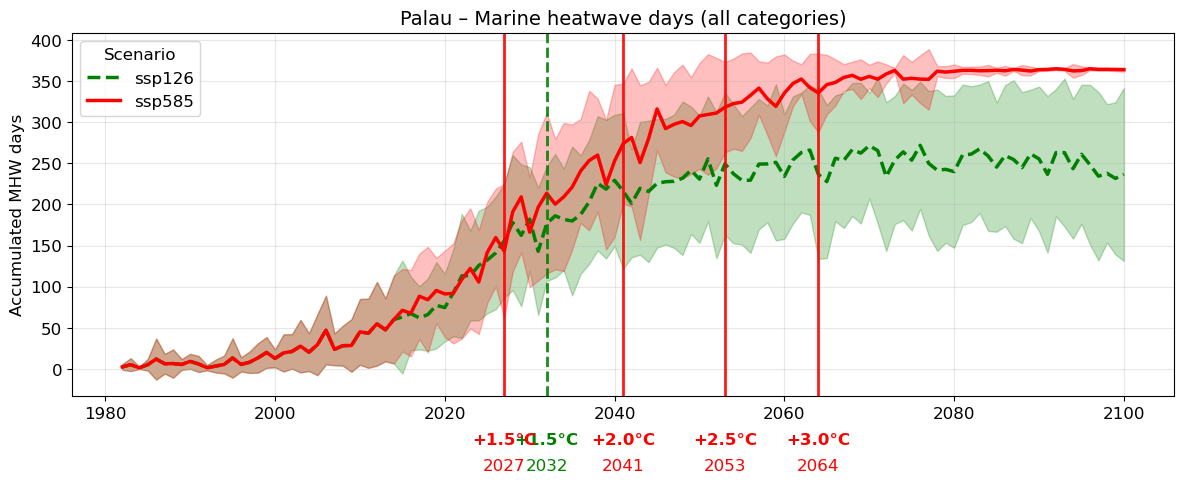

In [9]:
fig, ax = plot_mhw_total_accumulated(ds_mhw, scenario_info, scenarios=mhw_scenarios, warming_levels=incr_temps,
                                     delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "mhw_total_days", site_tag)

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_mhw_stacked_palau_psw00040309_lat7p337_lon134p477.png')

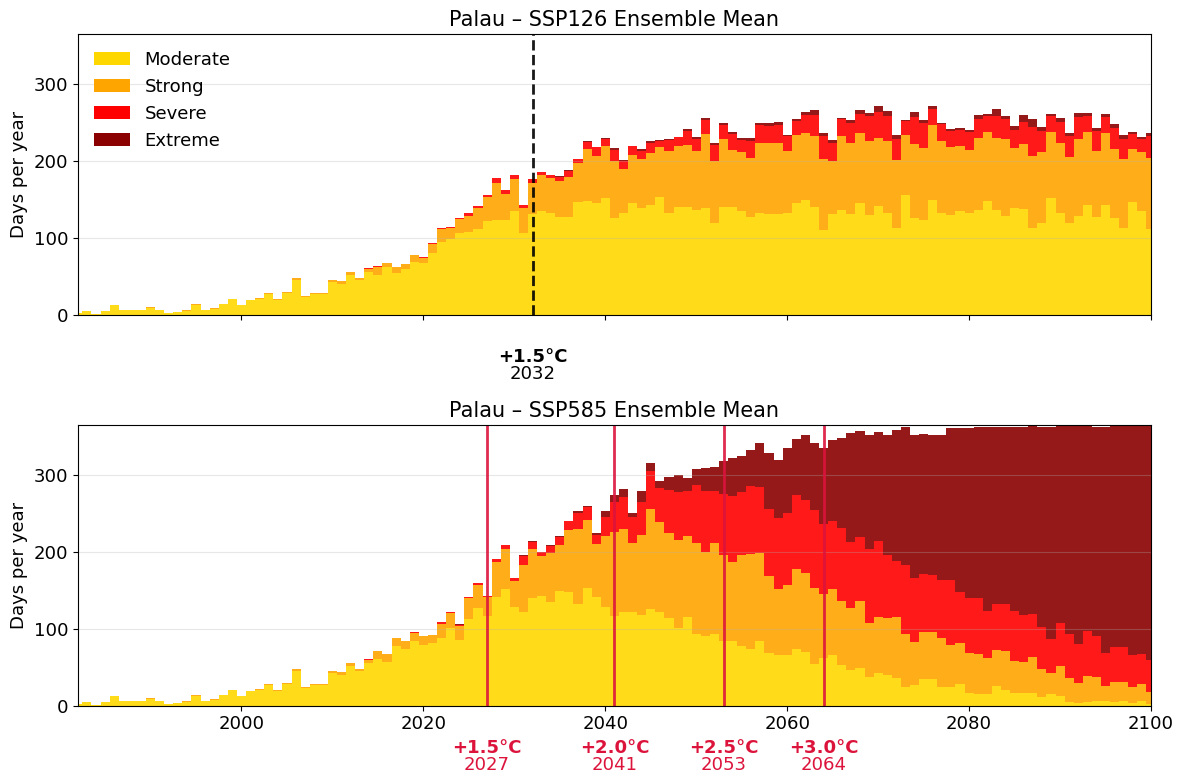

In [10]:
fig, axes = plot_stacked_mhw_by_warming(ds_mhw, scenario_info, var_analysis="mhw_cats_dpy", scenarios=mhw_scenarios,
                                        warming_levels=incr_temps, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "mhw_stacked", site_tag)

In [11]:
baseline = ds_mhw.sel(time=slice("1982", "2002")).mhw_cats_dpy.mean(dim=["time", "scenario", "model"]).squeeze()
print("Mean MHW days per year in 1982–2002 by category:", dict(zip(["Moderate", "Strong", "Severe", "Extreme"], baseline.values.round(1))))

Mean MHW days per year in 1982–2002 by category: {'Moderate': np.float64(8.4), 'Strong': np.float64(0.3), 'Severe': np.float64(0.0), 'Extreme': np.float64(0.0)}


### MHW categories at global warming levels (SSP5-8.5)

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_mhw_categories_gwl_ssp585_palau_psw00040309_lat7p337_lon134p477.png')

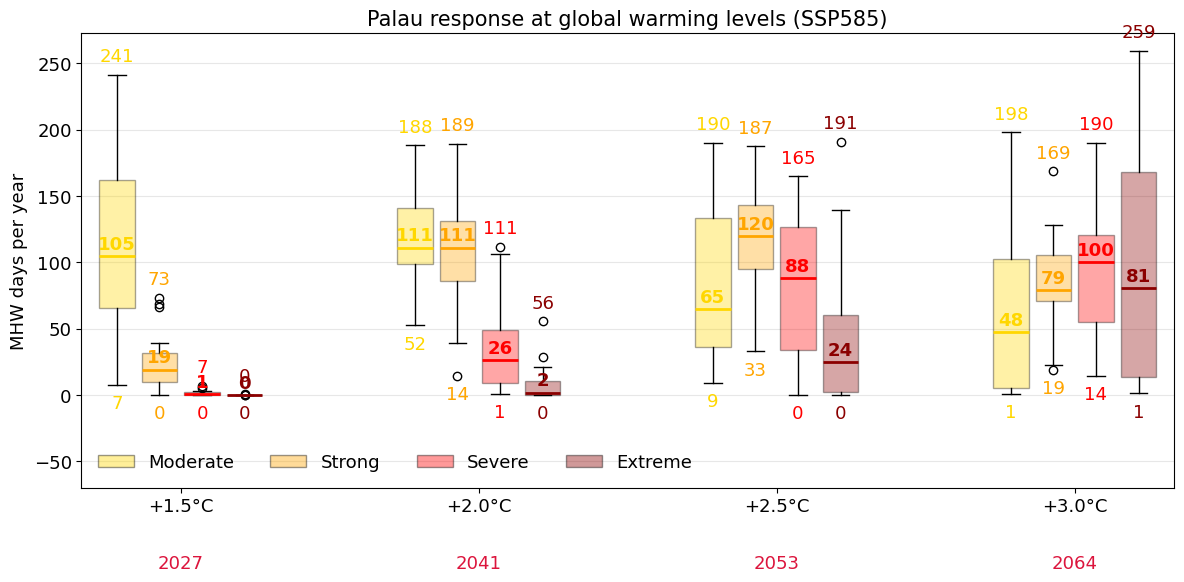

In [12]:
fig, ax = plot_box_mhw_categories_by_warming(ds_mhw, scenario_info, var_analysis="mhw_cats_dpy",
                                             var_analysis_label="MHW days per year", scenario="ssp585",
                                             delta_t=delta_t, texts=True, n_f=0, fontsize=13, site_label=site_label)
prj.save_figure(fig, fig_dir, "mhw_categories_gwl_ssp585", site_tag)

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_mhw_categories_violin_ssp585_palau_psw00040309_lat7p337_lon134p477.png')

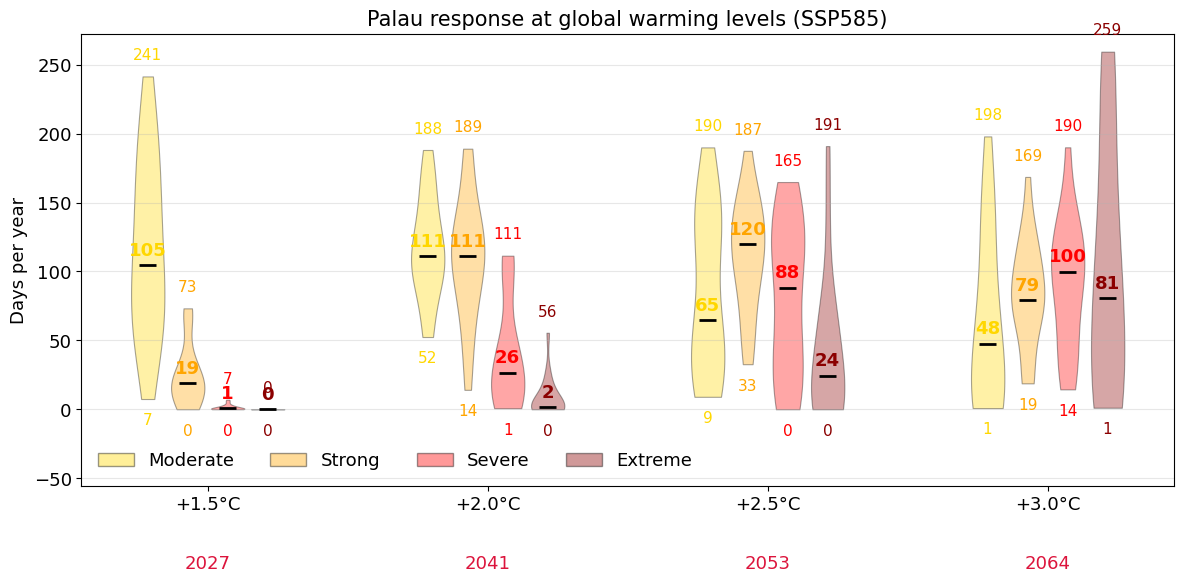

In [13]:
fig, ax = plot_violin_mhw_categories_by_warming(ds_mhw, scenario_info, var_analysis="mhw_cats_dpy",
                                                var_analysis_label="Days per year", scenario="ssp585",
                                                delta_t=delta_t, n_f=0, fontsize=13, site_label=site_label)
prj.save_figure(fig, fig_dir, "mhw_categories_violin_ssp585", site_tag)

In [14]:
table = prj.mhw_gwl_summary(ds_mhw, scenario_info)
prj.save_table(table, tables_dir, "mhw_categories_gwl", site_tag)
table

,Scenario,Warming level,Year,Category,Models,Median,P10,P90,Min,Max
0,SSP126,+1.5°C,2032,Moderate,18,136.1,72.6,189.8,35.1,231.5
1,SSP126,+1.5°C,2032,Strong,18,39.0,5.6,82.7,2.1,84.9
2,SSP126,+1.5°C,2032,Severe,18,2.2,0.0,13.4,0.0,22.2
3,SSP126,+1.5°C,2032,Extreme,18,0.0,0.0,0.5,0.0,1.4
4,SSP585,+1.5°C,2027,Moderate,18,104.6,46.5,200.4,7.4,241.5
5,SSP585,+1.5°C,2027,Strong,18,19.0,1.1,67.1,0.0,73.2
6,SSP585,+1.5°C,2027,Severe,18,0.6,0.0,3.6,0.0,6.9
7,SSP585,+1.5°C,2027,Extreme,18,0.0,0.0,0.2,0.0,0.3
8,SSP585,+2.0°C,2041,Moderate,18,111.0,70.6,168.9,52.4,188.1
9,SSP585,+2.0°C,2041,Strong,18,111.0,51.5,164.5,14.1,189.1
